In [1]:
import json

import numpy as np
import cupy as cp

import matplotlib.pyplot as plt

from discrete_time_extrusion.Translocator import Translocator

from discrete_time_extrusion.boundaries.NullBoundary import NullBoundary
from discrete_time_extrusion.extruders.MultistateExtruder import MultistateExtruder

In [2]:
# Simulate 10 chains comprised of 5820 sites of 2.5 nm (~8 bp) each 
number_of_chains = 20
chain_length = 5820

In [3]:
# Set simulation constants
step_size_nm = 40
site_size_nm = 2.5

site_size_bp = site_size_nm/0.3
step_size = int(step_size_nm/site_size_nm)

kT = 4.278

In [4]:
# Set chain extremities
chain_bounds = [[i*chain_length, (i+1)*chain_length-1] for i in range(number_of_chains)]

In [5]:
# Place two CTCF domains of 4 sites each, 500 sites off-center of each chain
offset = 500
l_ctcf = 4

types = ["DNA", "CTCF"]

In [6]:
# Set corresponding locus types
typeids = np.zeros(chain_length, dtype=int)

typeids[chain_length//2-offset-l_ctcf+1:chain_length//2-offset+1] = types.index('CTCF')
typeids[chain_length//2+offset:chain_length//2+offset+l_ctcf] = types.index('CTCF')

In [7]:
# Fetch JDM-parametrized extrusion dictionary
with open("../data/extrusion_dict_jdm.json", 'r') as dict_file:
    extrusion_dict = json.load(dict_file)

In [8]:
# Ensure consistent lattice size
extrusion_dict['monomers_per_replica'] = chain_length
extrusion_dict['number_of_replica'] = number_of_chains

extrusion_dict['LEF_separation'] = chain_length 

In [9]:
# Create translocator object
translocator = Translocator(MultistateExtruder,
                            NullBoundary,
                            types,
                            typeids,
                            [],
                            [],
                            chain_bounds,
                            device='CPU',
                            **extrusion_dict)

In [10]:
# Simulate 30s of physical time
simulation_time = int(30 / translocator.time_unit)

In [11]:
# Chain tension from relative extension
def compute_doubletethered_tensions(r_ee, positions, lp_nm=50):
    l1 = positions[:, 0] % chain_length
    l2 = chain_length - (positions[:, 1] % chain_length)
    
    l = l1 + l2
    x = r_ee / l

    f = .25/(1-x)**2 - .25 + x - 0.5164228*x**2 - 2.737418*x**3 + 16.07497*x**4 - 38.87607*x**5 + 39.49944*x**6 - 14.17718*x**7

    return site_size_nm/lp_nm * np.tile(f[:, None], (1, 2)) # in kT/model unit length

In [12]:
# Run simulation with fixed end-to-end distance of 50% contour length
r_ee = np.ones(number_of_chains, dtype=np.float64) * 0.5 * chain_length

states = np.zeros((simulation_time, translocator.extrusion_engine.number), dtype=np.int64)
tensions = np.zeros((simulation_time, translocator.extrusion_engine.number), dtype=np.float64)
directions = np.zeros((simulation_time, translocator.extrusion_engine.number), dtype=np.int64)

trajectory = np.zeros((simulation_time, translocator.extrusion_engine.number, 2), dtype=np.float64)

for timestep in range(simulation_time):
    positions = translocator.extrusion_engine.positions.copy()
    tension_array = compute_doubletethered_tensions(r_ee, positions)
    
    translocator.run(1, tension_array=tension_array, step_size=step_size, mode='asymmetric')

    tensions[timestep] = tension_array[:, 0].copy()
    states[timestep] = translocator.extrusion_engine.states.copy()
    directions[timestep] = translocator.extrusion_engine.directions.copy()
    
    trajectory[timestep] = np.where(positions > 0, positions, np.nan)

/home1/tortora/.conda/envs/cuda-sandbox/lib/python3.10/site-packages/discrete_time_extrusion/extruders/EngineFactory.py:72: UserWarning: Running lattice diffusion on the CPU using Numba
  warnings.warn("Running lattice diffusion on the CPU using Numba")
/home1/tortora/.conda/envs/cuda-sandbox/lib/python3.10/site-packages/discrete_time_extrusion/extruders/EngineFactory.py:130: UserWarning: Running lattice extrusion on the CPU using Numba
  warnings.warn("Running lattice extrusion on the CPU using Numba")
/home1/tortora/.conda/envs/cuda-sandbox/lib/python3.10/site-packages/discrete_time_extrusion/extruders/EngineFactory.py:72: UserWarning: Running lattice diffusion on the CPU using Numba
  warnings.warn("Running lattice diffusion on the CPU using Numba")
/home1/tortora/.conda/envs/cuda-sandbox/lib/python3.10/site-packages/discrete_time_extrusion/extruders/EngineFactory.py:130: UserWarning: Running lattice extrusion on the CPU using Numba
  warnings.warn("Running lattice extrusion on the 

In [13]:
# Convert arrays to phyical units
times = np.arange(simulation_time) * translocator.time_unit

tensions_pN = tensions * kT/site_size_nm
trajectory_kb = (trajectory  % chain_length) * site_size_bp / 1000.

In [14]:
# CTCF boundary positions for plotting
y11 = (chain_length//2-offset-l_ctcf+1) * site_size_bp / 1000.
y12 = (chain_length//2-offset+1) * site_size_bp / 1000.

y21 = (chain_length//2+offset) * site_size_bp / 1000.
y22 = (chain_length//2+offset+l_ctcf) * site_size_bp / 1000.

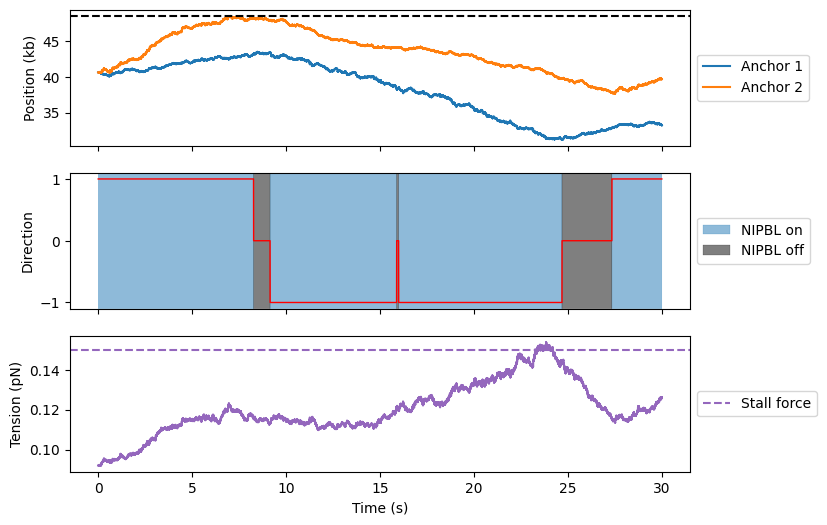

In [18]:
# Plot kymograph for individual cohesins
cohesin_id = 2

fig, (ax1, ax2, ax3) = plt.subplots(nrows=3, ncols=1, sharex=True, figsize=(8,6))

ax1.plot(times, trajectory_kb[:, cohesin_id, 0], label=r'Anchor 1', color='C0')
ax1.plot(times, trajectory_kb[:, cohesin_id, 1], label=r'Anchor 2', color='C1')

y1, y2 =ax1.get_ylim()

ax1.fill_between(times, y11, y12, color='C2', alpha=0.5, lw=0.25)
ax1.fill_between(times, y21, y22, color='C2', alpha=0.5, lw=0.25)

ax1.axhline(0, color='k', ls='--', lw=1.5)
ax1.axhline(chain_length * site_size_bp / 1000., color='k', ls='--', lw=1.5)

ax1.set_ylim([y1,y2])

ax1.set_ylabel('Position (kb)')

ax2.plot(times, np.where(states[:,cohesin_id] == 1, 2*directions[:,cohesin_id]-1, 0), lw=1, color='r')
y1, y2 =ax2.get_ylim()

ax2.fill_between(times, y1, y2, where=states[:,cohesin_id] == 1, color='C0', alpha=0.5, label=r'NIPBL on', lw=0.25)
ax2.fill_between(times, y1, y2, where=states[:,cohesin_id] != 1, color='k', alpha=0.5, label=r'NIPBL off', lw=0.25)

ax2.set_ylim([y1,y2])
ax2.set_ylabel('Direction')

ax3.plot(times, tensions_pN[:,cohesin_id], color='C4')
ax3.axhline(0.15, ls='--', color='C4', label=r'Stall force')

ax3.set_xlabel('Time (s)')
ax3.set_ylabel('Tension (pN)')

ax1.legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax2.legend(loc='center left', bbox_to_anchor=(1, 0.5))
ax3.legend(loc='center left', bbox_to_anchor=(1, 0.5))

plt.show()